# Proyecto Random Forest: prediccion de diabetes

Objetivo: predecir `Outcome` (0 = sin diabetes, 1 = con diabetes) con un bosque aleatorio y compararlo con el arbol del proyecto anterior.

Nota: el conjunto de test no se usa hasta la evaluacion final. Todas las decisiones se toman con validacion cruzada sobre train.

## Bloque 1: datos y particion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

SEED = 42

df = pd.read_csv("../diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
X = df.drop(columns="Outcome")
y = df["Outcome"]

# misma particion que en el proyecto del arbol (80/20, semilla 42, estratificada)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(X_train.shape, X_test.shape)
print("Proporcion de diabetes en train:", round(y_train.mean(), 3))
print("Proporcion de diabetes en test: ", round(y_test.mean(), 3))

(614, 8) (154, 8)
Proporcion de diabetes en train: 0.349
Proporcion de diabetes en test:  0.351


Los ceros imposibles de Glucose, BloodPressure, SkinThickness, Insulin y BMI se convierten en NaN. Pregnancies se deja igual porque ahi el cero es valido. La imputacion con la mediana se hace dentro del Pipeline, de modo que en cada fold se calcula solo con los datos de entrenamiento de ese fold.

In [3]:
COLS_CERO = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

def limpiar(X):
    X = X.copy()
    X[COLS_CERO] = X[COLS_CERO].replace(0, np.nan)
    return X

X_train = limpiar(X_train)
X_test = limpiar(X_test)

print((X_train.isna().mean() * 100).round(1))

Pregnancies                  0.0
Glucose                      0.7
BloodPressure                3.7
SkinThickness               28.5
Insulin                     47.2
BMI                          1.5
DiabetesPedigreeFunction     0.0
Age                          0.0
dtype: float64


## Bloque 2: arbol frente a bosque con valores por defecto

Antes de ajustar nada comparamos tres modelos con la misma validacion cruzada estratificada de 5 folds sobre train: un arbol por defecto, el arbol elegido en el proyecto anterior (gini, max_depth=6, min_samples_leaf=30, max_features=0.5) y un bosque por defecto (100 arboles). Se informan accuracy, recall y F1 de la clase con diabetes.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def pipeline(modelo):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("modelo", modelo),
    ])

modelos = {
    "arbol por defecto": pipeline(DecisionTreeClassifier(random_state=SEED)),
    "arbol proyecto anterior": pipeline(DecisionTreeClassifier(
        criterion="gini", max_depth=6, min_samples_leaf=30,
        max_features=0.5, random_state=SEED)),
    "bosque por defecto": pipeline(RandomForestClassifier(random_state=SEED, n_jobs=-1)),
}

filas = {}
for nombre, m in modelos.items():
    r = cross_validate(m, X_train, y_train, cv=cv,
                       scoring=["accuracy", "recall", "f1"], n_jobs=-1)
    filas[nombre] = {
        "accuracy": r["test_accuracy"].mean(),
        "recall": r["test_recall"].mean(),
        "f1": r["test_f1"].mean(),
        "f1 std": r["test_f1"].std(),
    }

tabla_base = pd.DataFrame(filas).T.round(3)
tabla_base

,accuracy,recall,f1,f1 std
arbol por defecto,0.673,0.580,0.552,0.027
arbol proyecto anterior,0.764,0.687,0.670,0.032
bosque por defecto,0.761,0.575,0.626,0.027


**Conclusiones del bloque 2**

- El bosque por defecto mejora mucho al arbol por defecto: accuracy 0.761 frente a 0.673 y F1 0.626 frente a 0.552. Promediar 100 arboles reduce el sobreajuste de un arbol sin limite de profundidad.
- No supera al arbol del proyecto anterior, que ya estaba ajustado (accuracy 0.764, F1 0.670). En accuracy empatan; en F1 el arbol queda 0.044 por encima, algo mas que una desviacion tipica entre folds (0.03).
- El bosque deja pasar mas enfermos: recall 0.575 frente a 0.687. Con 35% de positivos y umbral 0.5, tiende a favorecer la clase mayoritaria.
- Un bosque sin ajustar no basta. El siguiente bloque ajusta n_estimators y max_depth y mide F1 ademas de accuracy.

## Bloque 3: efecto de n_estimators y max_depth

Se varian los dos hiperparametros del bosque que mas influyen: el numero de arboles (`n_estimators`) y la profundidad maxima de cada arbol (`max_depth`, donde `None` significa sin limite). Todas las combinaciones se evaluan con la misma validacion cruzada sobre train. Se guarda tambien el F1 en train para ver el sobreajuste.

In [5]:
valores_n = [10, 25, 50, 100, 200, 400]
valores_depth = [2, 4, 6, 8, 10, None]

filas = []
for d in valores_depth:
    for n in valores_n:
        m = pipeline(RandomForestClassifier(
            n_estimators=n, max_depth=d, random_state=SEED, n_jobs=-1))
        r = cross_validate(m, X_train, y_train, cv=cv, return_train_score=True,
                           scoring=["accuracy", "recall", "f1"])
        filas.append({
            "max_depth": "None" if d is None else d,
            "n_estimators": n,
            "accuracy": r["test_accuracy"].mean(),
            "recall": r["test_recall"].mean(),
            "f1": r["test_f1"].mean(),
            "f1_train": r["train_f1"].mean(),
        })

tabla_hp = pd.DataFrame(filas)
tabla_hp.sort_values("f1", ascending=False).head(5).round(3)

,max_depth,n_estimators,accuracy,recall,f1,f1_train
29,10,400,0.774,0.603,0.650,0.995
34,None,200,0.772,0.603,0.650,1.000
28,10,200,0.772,0.603,0.649,0.994
17,6,400,0.775,0.580,0.643,0.844
27,10,100,0.767,0.598,0.642,0.992


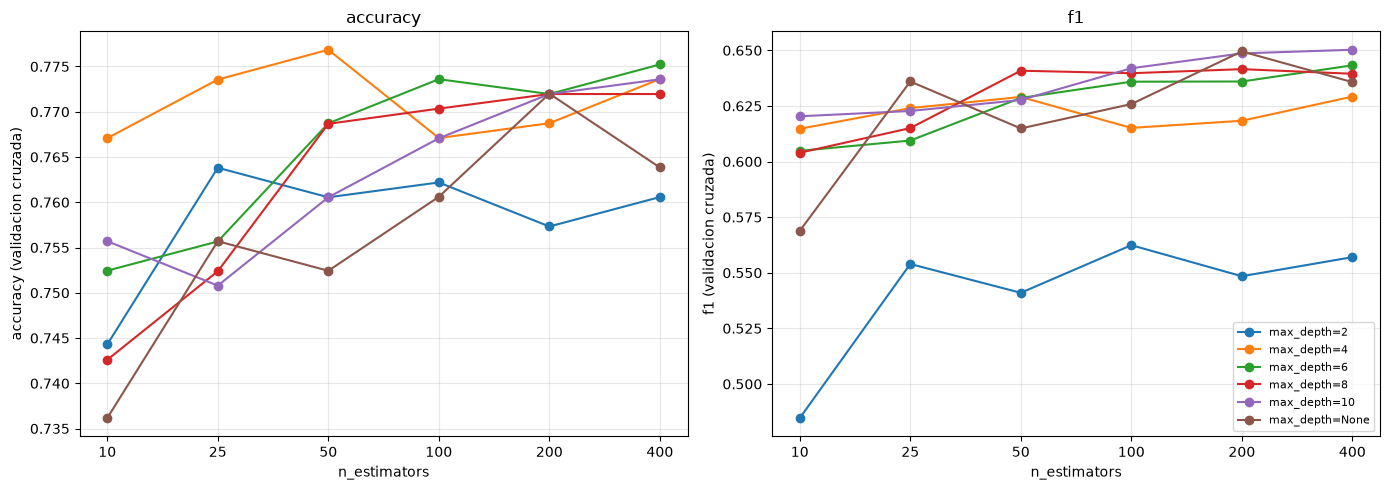

n_estimators,10,25,50,100,200,400
max_depth,,,,,,
2,0.073,0.050,0.037,0.029,0.043,0.036
4,0.101,0.101,0.101,0.110,0.110,0.095
6,0.210,0.216,0.199,0.205,0.206,0.200
8,0.312,0.323,0.303,0.306,0.311,0.318
10,0.333,0.357,0.360,0.350,0.346,0.344
None,0.400,0.360,0.385,0.374,0.350,0.364


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
posiciones = range(len(valores_n))

for ax, metrica in zip(axes, ["accuracy", "f1"]):
    for d in tabla_hp["max_depth"].unique():
        sub = tabla_hp[tabla_hp["max_depth"] == d]
        ax.plot(posiciones, sub[metrica], marker="o", label=f"max_depth={d}")
    ax.set_xticks(list(posiciones))
    ax.set_xticklabels(valores_n)
    ax.set_xlabel("n_estimators")
    ax.set_ylabel(metrica + " (validacion cruzada)")
    ax.set_title(metrica)
    ax.grid(alpha=0.3)

axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# sobreajuste: F1 en train menos F1 en validacion
brecha = tabla_hp.assign(brecha=tabla_hp["f1_train"] - tabla_hp["f1"])
orden = [2, 4, 6, 8, 10, "None"]
brecha.pivot(index="max_depth", columns="n_estimators", values="brecha").loc[orden].round(3)

**Conclusiones del bloque 3**

- n_estimators: pasar de 10 a 100 arboles mejora el F1 (por ejemplo con max_depth=10 sube de 0.620 a 0.642), y de 200 en adelante la curva se aplana. Mas arboles no sobreajustan, pero tampoco aportan mucho mas.
- max_depth: con 2 el modelo no aprende lo suficiente (F1 cercano a 0.55). Entre 4 y 10 el F1 de validacion se mueve poco (0.62 a 0.65), mientras que el F1 de train sube de 0.73 a 1.00 y la brecha crece de 0.10 a 0.35-0.40. Mas profundidad aumenta el sobreajuste sin mejora real.
- Las mejores combinaciones (F1 0.650, accuracy 0.774) quedan por debajo del arbol del proyecto anterior en F1 (0.670) y apenas por encima en accuracy (0.775 frente a 0.764). Esas diferencias son menores que la desviacion entre folds (0.03), asi que con estos dos hiperparametros el bosque no supera claramente al arbol ajustado.
- El recall sigue en torno a 0.60, por debajo del 0.687 del arbol. El siguiente bloque ajusta tambien los hiperparametros que hicieron bueno al arbol (min_samples_leaf y max_features) y class_weight, optimizando F1.

## Bloque 4: busqueda de hiperparametros optimizando F1

Se prueban 64 combinaciones de max_depth, min_samples_leaf, max_features y class_weight, con 200 arboles, usando la misma validacion cruzada sobre train. El criterio para elegir es el F1 de la clase con diabetes; accuracy y recall se registran para comparar.

In [7]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "modelo__n_estimators": [200],
    "modelo__max_depth": [4, 6, 8, None],
    "modelo__min_samples_leaf": [1, 5, 15, 30],
    "modelo__max_features": ["sqrt", 0.5],
    "modelo__class_weight": [None, "balanced"],
}

busqueda = GridSearchCV(
    pipeline(RandomForestClassifier(random_state=SEED)),
    param_grid, cv=cv, refit="f1", n_jobs=-1,
    scoring=["accuracy", "recall", "f1"], return_train_score=True,
)
busqueda.fit(X_train, y_train)

res = pd.DataFrame(busqueda.cv_results_)
nombres = {
    "param_modelo__max_depth": "max_depth",
    "param_modelo__min_samples_leaf": "min_samples_leaf",
    "param_modelo__max_features": "max_features",
    "param_modelo__class_weight": "class_weight",
}
metricas = ["mean_test_accuracy", "mean_test_recall", "mean_test_f1",
            "std_test_f1", "mean_train_f1"]

top = (res.sort_values("mean_test_f1", ascending=False)
          .head(8)[list(nombres) + metricas].rename(columns=nombres))

print("Mejores parametros:", busqueda.best_params_)
print("F1 de validacion cruzada del mejor:", round(busqueda.best_score_, 3))
top.round(3)

Mejores parametros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': 4, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
F1 de validacion cruzada del mejor: 0.702


,max_depth,min_samples_leaf,max_features,class_weight,mean_test_accuracy,mean_test_recall,mean_test_f1,std_test_f1,mean_train_f1
33,4,5,sqrt,balanced,0.770,0.776,0.702,0.013,0.767
55,8,30,0.5,balanced,0.772,0.752,0.697,0.016,0.743
47,6,30,0.5,balanced,0.772,0.752,0.697,0.016,0.743
63,None,30,0.5,balanced,0.772,0.752,0.697,0.016,0.743
39,4,30,0.5,balanced,0.772,0.752,0.697,0.012,0.741
46,6,15,0.5,balanced,0.769,0.762,0.697,0.014,0.763
32,4,1,sqrt,balanced,0.767,0.766,0.697,0.017,0.781
61,None,5,0.5,balanced,0.770,0.752,0.696,0.018,0.850


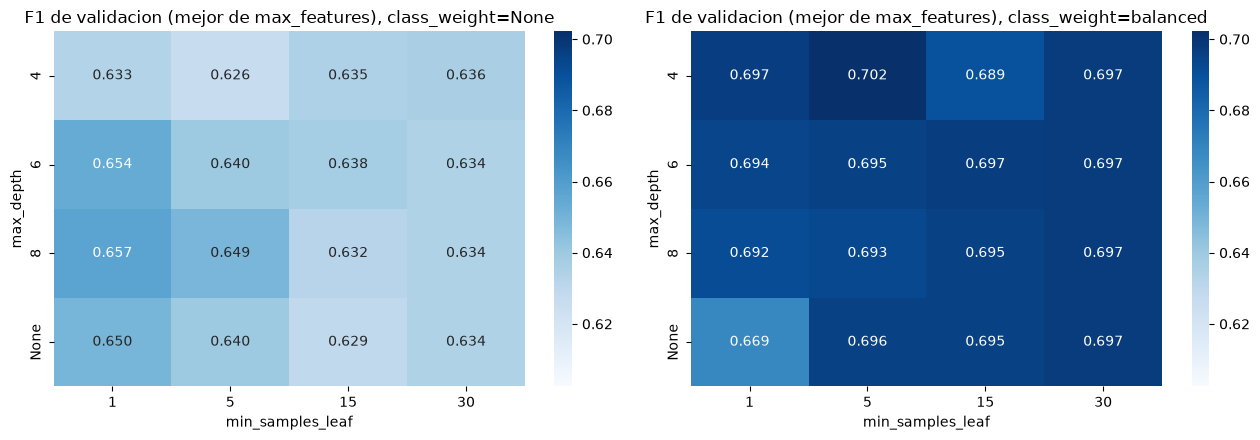

In [8]:
def texto(v):
    return "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v)

res["max_depth"] = res["param_modelo__max_depth"].map(texto)
res["min_samples_leaf"] = res["param_modelo__min_samples_leaf"].astype(int)
res["class_weight"] = res["param_modelo__class_weight"].map(texto)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, cw in zip(axes, ["None", "balanced"]):
    mapa = (res[res["class_weight"] == cw]
            .pivot_table(index="max_depth", columns="min_samples_leaf",
                         values="mean_test_f1", aggfunc="max")
            .loc[["4", "6", "8", "None"]])
    sns.heatmap(mapa, annot=True, fmt=".3f", cmap="Blues",
                vmin=res["mean_test_f1"].min(), vmax=res["mean_test_f1"].max(), ax=ax)
    ax.set_title(f"F1 de validacion (mejor de max_features), class_weight={cw}")

plt.tight_layout()
plt.show()

**Conclusiones del bloque 4**

- class_weight="balanced" es lo que mas pesa: el mejor F1 con balanced es 0.702 y sin el no pasa de 0.657. Con balanced el recall sube de 0.60 a 0.78.
- La mejor combinacion (max_depth=4, min_samples_leaf=5, max_features="sqrt", balanced) da F1 0.702, recall 0.776 y accuracy 0.770 en validacion cruzada. Frente al arbol del proyecto anterior (F1 0.670, recall 0.687, accuracy 0.764) mejora el F1 en 0.032 y el recall en 0.089, con la misma accuracy.
- Hay una meseta: siete de las ocho mejores combinaciones quedan entre 0.696 y 0.697, y la diferencia con la primera (0.005) es menor que la desviacion entre folds (0.013 a 0.018). La mejor no es claramente mejor que las demas.
- El mejor max_depth (4) es el valor mas bajo probado, asi que la rejilla se extiende hacia abajo antes de elegir el modelo final.

## Bloque 5: comprobacion del borde de la rejilla

El mejor max_depth del bloque anterior fue el valor mas bajo probado. Se repite la busqueda con valores menores de max_depth y min_samples_leaf alrededor del mejor, solo con class_weight="balanced", que ya demostro ser lo que mas importa.

In [9]:
param_grid2 = {
    "modelo__n_estimators": [200],
    "modelo__max_depth": [2, 3, 4, 5],
    "modelo__min_samples_leaf": [3, 5, 8, 12],
    "modelo__max_features": ["sqrt", 0.5],
    "modelo__class_weight": ["balanced"],
}

busqueda2 = GridSearchCV(
    pipeline(RandomForestClassifier(random_state=SEED)),
    param_grid2, cv=cv, refit="f1", n_jobs=-1,
    scoring=["accuracy", "recall", "f1"], return_train_score=True,
)
busqueda2.fit(X_train, y_train)

res2 = pd.DataFrame(busqueda2.cv_results_)
res2["max_depth"] = res2["param_modelo__max_depth"].astype(int)
res2["min_samples_leaf"] = res2["param_modelo__min_samples_leaf"].astype(int)
res2["max_features"] = res2["param_modelo__max_features"].astype(str)

top2 = (res2.sort_values("mean_test_f1", ascending=False).head(8)
            [["max_depth", "min_samples_leaf", "max_features"] + metricas]
            .reset_index(drop=True))

print("Mejores parametros:", busqueda2.best_params_)
print("F1 de validacion cruzada del mejor:", round(busqueda2.best_score_, 3))
top2.round(3)

Mejores parametros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': 5, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 12, 'modelo__n_estimators': 200}
F1 de validacion cruzada del mejor: 0.702


,max_depth,min_samples_leaf,max_features,mean_test_accuracy,mean_test_recall,mean_test_f1,std_test_f1,mean_train_f1
0,5,12,0.5,0.774,0.766,0.702,0.015,0.764
1,4,5,sqrt,0.770,0.776,0.702,0.013,0.767
2,5,5,sqrt,0.767,0.780,0.701,0.013,0.785
3,3,8,0.5,0.774,0.752,0.699,0.017,0.749
4,5,3,sqrt,0.769,0.766,0.698,0.017,0.796
5,5,3,0.5,0.769,0.766,0.698,0.020,0.796
6,4,8,sqrt,0.767,0.771,0.698,0.011,0.763
7,3,5,0.5,0.772,0.752,0.697,0.018,0.753


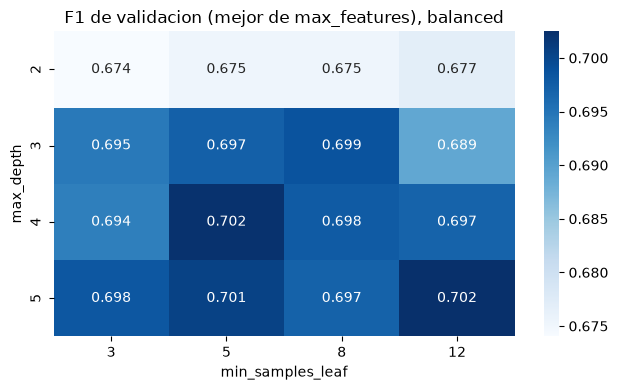

In [10]:
mapa2 = res2.pivot_table(index="max_depth", columns="min_samples_leaf",
                         values="mean_test_f1", aggfunc="max")

plt.figure(figsize=(6.5, 4))
sns.heatmap(mapa2, annot=True, fmt=".3f", cmap="Blues")
plt.title("F1 de validacion (mejor de max_features), balanced")
plt.tight_layout()
plt.show()

**Conclusiones del bloque 5**

- Con max_depth=2 el F1 baja a 0.674-0.677 en todas las combinaciones: no aprende lo suficiente. De 3 a 5 el F1 queda entre 0.689 y 0.702.
- El mejor ya no esta en el borde. Tres combinaciones empatan casi exactamente (F1 0.702, 0.702 y 0.701, con desviacion entre folds de 0.013 a 0.015), y el bloque 4 mostro que profundidades y hojas mayores tambien dan 0.696-0.697. No hay un ganador claro: hay una meseta.
- Criterio de desempate: entre las combinaciones que empatan (a menos de 0.002 del mejor F1) se elige la de arboles mas simples. Modelo final: max_depth=4, min_samples_leaf=5, max_features="sqrt", class_weight="balanced", n_estimators=200. Ademas tiene el recall mas alto del grupo (0.776) y la menor desviacion (0.013).

## Bloque 6: evaluacion final en test y guardado del modelo

Es la unica vez que se usa el conjunto de test. Se entrena el modelo elegido con todo train y se evalua en test junto al arbol del proyecto anterior, reentrenado con los mismos datos, y a una linea base que siempre responde "sin diabetes".

Linea base (siempre sin diabetes), accuracy: 0.649


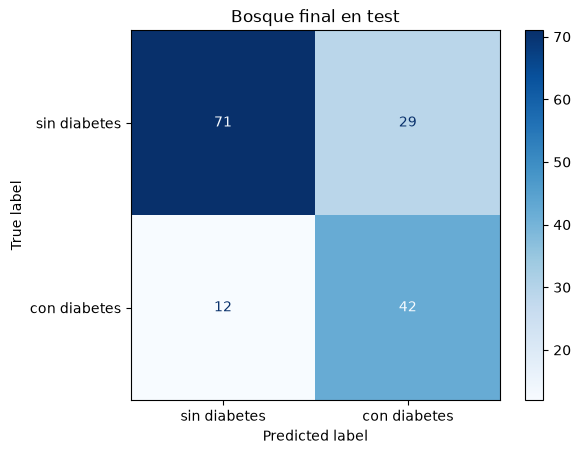

Matriz de confusion (filas = real, columnas = predicho):
[[71 29]
 [12 42]]


,accuracy,recall,precision,f1
bosque final,0.734,0.778,0.592,0.672
arbol proyecto anterior,0.727,0.796,0.581,0.672


In [11]:
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

modelo_final = pipeline(RandomForestClassifier(
    n_estimators=200, max_depth=4, min_samples_leaf=5, max_features="sqrt",
    class_weight="balanced", random_state=SEED, n_jobs=-1))
modelo_final.fit(X_train, y_train)

arbol_anterior = modelos["arbol proyecto anterior"]
arbol_anterior.fit(X_train, y_train)

def metricas_test(m):
    p = m.predict(X_test)
    return {"accuracy": accuracy_score(y_test, p), "recall": recall_score(y_test, p),
            "precision": precision_score(y_test, p), "f1": f1_score(y_test, p)}

tabla_test = pd.DataFrame({
    "bosque final": metricas_test(modelo_final),
    "arbol proyecto anterior": metricas_test(arbol_anterior),
}).T.round(3)

print("Linea base (siempre sin diabetes), accuracy:", round(1 - y_test.mean(), 3))

pred_final = modelo_final.predict(X_test)
cm = confusion_matrix(y_test, pred_final)
ConfusionMatrixDisplay(cm, display_labels=["sin diabetes", "con diabetes"]).plot(cmap="Blues")
plt.title("Bosque final en test")
plt.show()

print("Matriz de confusion (filas = real, columnas = predicho):")
print(cm)
tabla_test

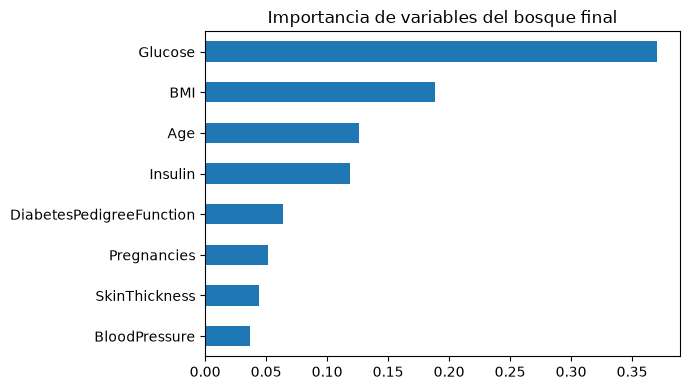

Glucose                     0.371
BMI                         0.188
Age                         0.126
Insulin                     0.119
DiabetesPedigreeFunction    0.064
Pregnancies                 0.051
SkinThickness               0.044
BloodPressure               0.037
dtype: float64


In [12]:
importancias = pd.Series(
    modelo_final.named_steps["modelo"].feature_importances_, index=X_train.columns
).sort_values()

importancias.plot.barh(figsize=(7, 4))
plt.title("Importancia de variables del bosque final")
plt.tight_layout()
plt.show()

print(importancias.sort_values(ascending=False).round(3))

El modelo guardado es un Pipeline completo (imputacion con la mediana mas el bosque). Espera recibir los datos ya pasados por la funcion `limpiar` (ceros imposibles convertidos en NaN); no hace falta escalar.

In [13]:
import os
import pickle

os.makedirs("../models", exist_ok=True)
nombre = "bosque_balanced_depth4_leaf5_featsqrt_n200_seed42.pkl"

with open(f"../models/{nombre}", "wb") as f:
    pickle.dump(modelo_final, f)

print(nombre, os.path.getsize(f"../models/{nombre}"), "bytes")

bosque_balanced_depth4_leaf5_featsqrt_n200_seed42.pkl 486346 bytes


**Conclusion del bloque 6 (evaluacion final en test).** El bosque final (200 arboles, max_depth=4, min_samples_leaf=5, max_features="sqrt", class_weight="balanced") obtiene en test accuracy 0.734, recall 0.778, precision 0.592 y F1 0.672. Supera la linea base (0.649) en accuracy y detecta 42 de 54 diabeticos. El arbol del proyecto anterior obtiene F1 0.672, es decir, un empate: la ventaja que el bosque mostraba en validacion cruzada (F1 0.702 contra 0.670) no se confirma de forma clara en test. El test tiene solo 154 filas y 54 positivos, por lo que diferencias de uno o dos casos cambian las metricas y no podemos concluir que un modelo sea mejor que el otro. Si se prioriza el recall, el arbol queda ligeramente por encima (0.796 contra 0.778); si se prioriza la precision, el bosque (0.592 contra 0.581). Glucose es la variable mas importante (0.371), seguida de BMI (0.188), Age (0.126) e Insulin (0.119), en linea con lo visto en el arbol. El modelo guardado es un Pipeline (imputador de mediana + bosque) y espera datos ya pasados por la funcion limpiar, sin escalado. Aprendizaje principal: un bosque no garantiza mejora sobre un arbol bien ajustado en un dataset pequeno; el valor esta en la estabilidad y en haber elegido hiperparametros con validacion cruzada y no con el test.